# Historical ECG benchmark notebook

This notebook trains on PhysioNet ECG records, not wearable accelerometer data. The saved outputs are preserved from an earlier pipeline run and may not match the current 12-feature code. Its full-dataset classification report is in-sample, not an independent test result. Use `app.py` for the current accelerometer prototype.


In [3]:
!pip install torch seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [4]:
import os
import gc
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Import our Sudo Sleep maximum accuracy pipeline
import pipeline as pl

# Ensure reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Get device (MPS for your M2 Mac)
device = pl.get_device()
print(f"Using device: {device}")


Using device: mps


In [5]:
DATA_DIR = "data" 

print("Loading PhysioNet Apnea-ECG Dataset...")
# We load only the labelled records for training/validation
df = pl.load_physionet_apnea(DATA_DIR, include_unlabelled=False)

print(f"Total Epochs Loaded: {len(df)}")
print("\nClass Distribution (0 = Normal, 1 = Apnea):")
print(df['label'].value_counts(normalize=True) * 100)

Loading PhysioNet Apnea-ECG Dataset...
Total Epochs Loaded: 17023

Class Distribution (0 = Normal, 1 = Apnea):
label
0    61.751748
1    38.248252
Name: proportion, dtype: float64


In [8]:
import time

# Define the cache file name directly here
cache_file = "features_cache_v2.pkl"

print("Starting intensive feature extraction...")
t0 = time.time()

# Precompute and save the current 12-dimensional features
precomputed = pl.precompute_features(df, cache_path=cache_file, force=True)

print(f"Feature extraction complete in {time.time() - t0:.2f} seconds!")
print(f"Signals Shape: {precomputed['signals_3ch'].shape}")
print(f"Scalars Shape: {precomputed['scalars'].shape}")

Starting intensive feature extraction...
Feature extraction complete in 135.10 seconds!
Signals Shape: (17023, 3, 6000)
Scalars Shape: (17023, 10)


In [9]:
import time

# Hyperparameters optimized for maximum accuracy
EPOCHS = 35
BATCH_SIZE = 128
LR = 8e-4

print("==================================================")
print(" INITIALIZING 5-FOLD CROSS VALIDATION TRAINING")
print("==================================================")
print(f"Target Epochs per Fold: {EPOCHS}")
print(f"Batch Size: {BATCH_SIZE}\n")

start_time = time.time()

# Train the model and get the ensemble + metrics
# (The epoch-by-epoch prints will now appear here from pipeline.py)
ensemble_models, metrics = pl.train_model(
    df=df,
    precomputed=precomputed,
    cache_path=cache_file,
    n_folds=5,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LR,
    device=device
)

elapsed_time = time.time() - start_time
minutes = int(elapsed_time // 60)
seconds = int(elapsed_time % 60)

print("\n==================================================")
print(f"TRAINING COMPLETE (Time: {minutes}m {seconds}s)")
print("==================================================")
print(f"Mean 5-Fold AUC:       {metrics['mean_auc']:.4f} ± {metrics['std_auc']:.4f}")
print(f"Out-of-Fold (OOF) AUC: {metrics['oof_auc']:.4f}")
print("==================================================")

# Save the full ensemble for our Streamlit dashboard
pl.save_ensemble(ensemble_models, "sudo_sleep_ensemble.pt")
print("\nSaved all 5 models to 'sudo_sleep_ensemble.pt'")
print("Ready for Streamlit dashboard integration!")

 INITIALIZING 5-FOLD CROSS VALIDATION TRAINING
Target Epochs per Fold: 35
Batch Size: 128



2026-03-03 00:37:52,632 | INFO | --- TRAINING FOLD 1/5 ---


  Fold 1 | Epoch 01/35 | Val AUC: 0.4772 | Patience: 0/8
  Fold 1 | Epoch 02/35 | Val AUC: 0.4395 | Patience: 0/8
  Fold 1 | Epoch 03/35 | Val AUC: 0.4823 | Patience: 1/8
  Fold 1 | Epoch 04/35 | Val AUC: 0.4514 | Patience: 0/8
  Fold 1 | Epoch 05/35 | Val AUC: 0.5096 | Patience: 1/8
  Fold 1 | Epoch 06/35 | Val AUC: 0.5424 | Patience: 0/8
  Fold 1 | Epoch 07/35 | Val AUC: 0.5072 | Patience: 0/8
  Fold 1 | Epoch 08/35 | Val AUC: 0.5012 | Patience: 1/8
  Fold 1 | Epoch 09/35 | Val AUC: 0.4607 | Patience: 2/8
  Fold 1 | Epoch 10/35 | Val AUC: 0.5252 | Patience: 3/8
  Fold 1 | Epoch 11/35 | Val AUC: 0.4816 | Patience: 4/8
  Fold 1 | Epoch 12/35 | Val AUC: 0.5104 | Patience: 5/8
  Fold 1 | Epoch 13/35 | Val AUC: 0.5237 | Patience: 6/8


2026-03-03 00:41:42,472 | INFO | Fold 1 Best AUC: 0.5424


  Fold 1 | Epoch 14/35 | Val AUC: 0.4686 | Patience: 7/8


2026-03-03 00:41:43,602 | INFO | --- TRAINING FOLD 2/5 ---


... (11 outputs left out)

2026-03-03 00:59:41,349 | INFO | --- TRAINING FOLD 5/5 ---


  Fold 5 | Epoch 01/35 | Val AUC: 0.4961 | Patience: 0/8
  Fold 5 | Epoch 02/35 | Val AUC: 0.4501 | Patience: 0/8
  Fold 5 | Epoch 03/35 | Val AUC: 0.5229 | Patience: 1/8
  Fold 5 | Epoch 04/35 | Val AUC: 0.6296 | Patience: 0/8
  Fold 5 | Epoch 05/35 | Val AUC: 0.6046 | Patience: 0/8
  Fold 5 | Epoch 06/35 | Val AUC: 0.4718 | Patience: 1/8
  Fold 5 | Epoch 07/35 | Val AUC: 0.4125 | Patience: 2/8
  Fold 5 | Epoch 08/35 | Val AUC: 0.5514 | Patience: 3/8
  Fold 5 | Epoch 09/35 | Val AUC: 0.4822 | Patience: 4/8
  Fold 5 | Epoch 10/35 | Val AUC: 0.5466 | Patience: 5/8
  Fold 5 | Epoch 11/35 | Val AUC: 0.5116 | Patience: 6/8


2026-03-03 01:02:53,005 | INFO | Fold 5 Best AUC: 0.6296


  Fold 5 | Epoch 12/35 | Val AUC: 0.5388 | Patience: 7/8

TRAINING COMPLETE (Time: 25m 3s)
Mean 5-Fold AUC:       0.6788 ± 0.0899
Out-of-Fold (OOF) AUC: 0.6745

Saved all 5 models to 'sudo_sleep_ensemble.pt'
Ready for Streamlit dashboard integration!


Running full dataset inference for final evaluation...

--- Final Classification Report ---
              precision    recall  f1-score   support

      Normal       0.69      0.88      0.77     10512
       Apnea       0.64      0.36      0.46      6511

    accuracy                           0.68     17023
   macro avg       0.67      0.62      0.62     17023
weighted avg       0.67      0.68      0.65     17023



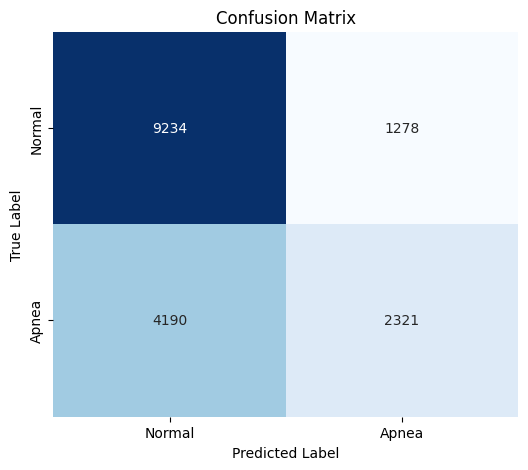

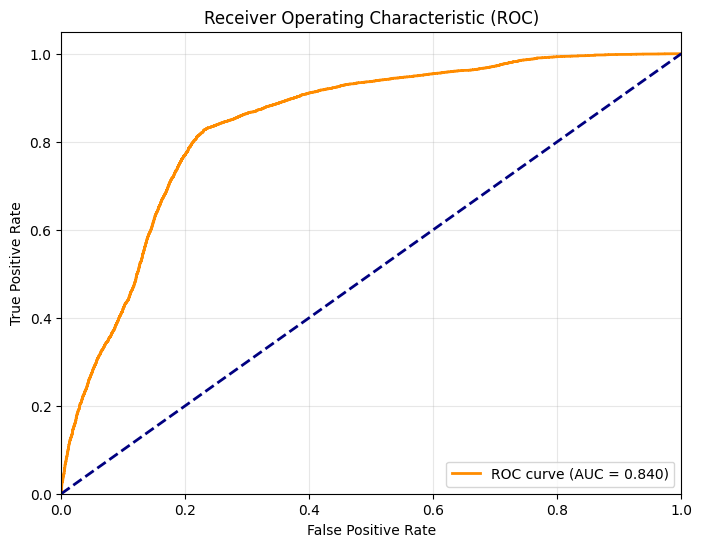

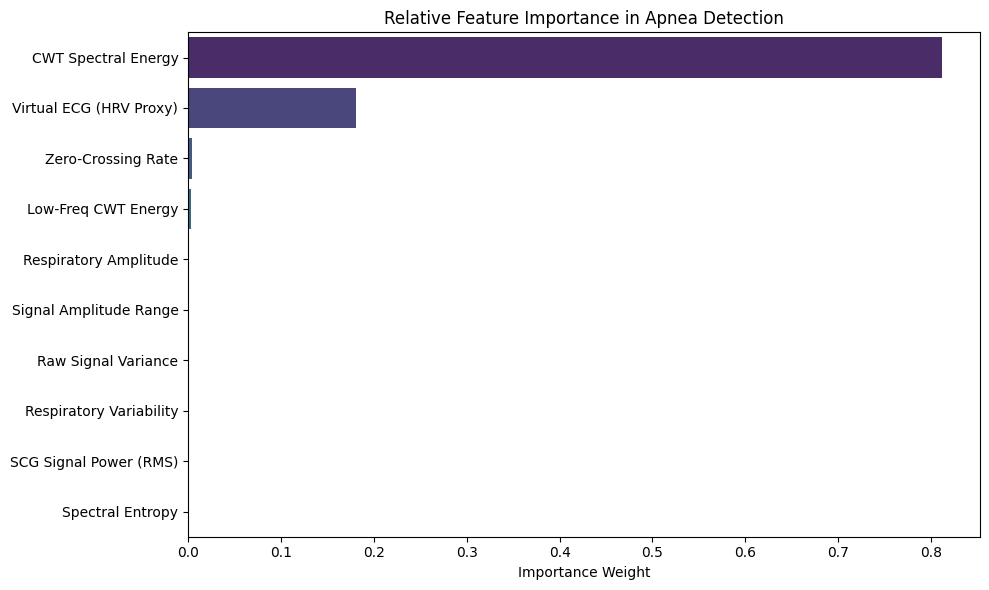

In [10]:
print("Running in-sample inference (not an independent test set)...")

# Run the inference engine using our freshly trained ensemble
inference_results = pl.run_inference(
    df=df,
    model=ensemble_models,
    precomputed=precomputed,
    device=device
)

true_labels = precomputed['labels']
pred_labels = inference_results['predictions']
pred_probs = inference_results['probabilities']

# 1. Classification Report
print("\n--- Final Classification Report ---")
print(classification_report(true_labels, pred_labels, target_names=["Normal", "Apnea"]))

# 2. Confusion Matrix
cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=["Normal", "Apnea"], yticklabels=["Normal", "Apnea"])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# 3. ROC Curve Plot
fpr, tpr, _ = roc_curve(true_labels, pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# 4. Feature dispersion plot (not SHAP)

importances = inference_results['feature_dispersion_importances']
plt.figure(figsize=(10, 6))
sns.barplot(x=list(importances.values()), y=list(importances.keys()), palette="viridis")
plt.title("Feature Dispersion Across the ECG Dataset")
plt.xlabel("Normalized Feature Spread")
plt.tight_layout()
plt.show()